# 기술통계: 원자료 → 분석 표본 → 단순 패턴 (코딩 2)

**목적:** 모형(Cox) 이전 단계에서 **원자료 → 분석 표본 → 단순 패턴**의 연결을 보여 준다.

- 입력: `out/analysis_table_v2.parquet` (1행 = 가게 1곳, 2013~2022년 개업, 서울 일반음식점)
- 주요 변수: `prior_closures` = 개업 직전 3년 동안 같은 칸(지번+층)에서 발생한 진짜 폐업 수
- 이 노트북의 숫자는 모두 **단순 비교(통제 전)** 이며, 인과 관계를 뜻하지 않는다.
- 공개 범위: 구 단위까지. 상호·주소·좌표·관리번호는 출력하지 않는다.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

# 한글 글꼴 (Windows / Mac / 그 외)
for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if any(f == z.name for z in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = f; break
plt.rcParams['axes.unicode_minus'] = False

# notebooks/ 안에서 열어도, 프로젝트 최상위에서 열어도 같은 경로가 되게
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'out'
sys.path.insert(0, str(ROOT))
from cox_models import prepare   # analysis_main.py와 같은 변수 가공

df = pd.read_parquet(OUT / 'analysis_table_v2.parquet')
print('가게', len(df), '곳 | 열', df.shape[1], '개')

가게 111484 곳 | 열 46 개


In [2]:
# 그룹별 가게 수, 이전 폐업 1회 이상 비율(%), 3년 안 폐업률(%)
def summary_by(data, group_col):
    g = data.groupby(group_col, dropna=False)
    table = pd.DataFrame({
        '가게 수': g.size(),
        '이전 폐업 1회 이상(%)': (g['prior_closures'].apply(lambda s: (s >= 1).mean()) * 100).round(1),
        '3년 안 폐업률(%)': (g['dead_3y'].mean() * 100).round(1),
    })
    return table

## 1. 표본 흐름표

전체 개업 → 단일 점포 칸(`single_unit_site == True`, 결정 D1) → 통제변수 결측 제외 (= 본분석 표본).
본분석 표본은 `analysis_main.py`와 같은 규칙으로 만든다 (M3 통제변수 결측 제외 + 생존 기간 0일 제외. M4 추가 변수는 결측을 0으로 채우므로 추가 제외 없음).

In [3]:
full, cat_cols, yr_cols, _ = prepare(df)
M3_controls = cat_cols + yr_cols + ['log_area', 'site_age_y', 'hex_closure_rate_3y',
                                    'hex_density_100', 'hex_density_100_sq', 'other_floor_closures']

step1 = full
step2 = step1[step1['single_unit_site'] == True]
step3 = step2.dropna(subset=M3_controls + ['prior_closures', 'duration_days'])
step3 = step3[step3['duration_days'] > 0]
main = step3.copy()   # 본분석 표본

flow = pd.DataFrame({
    '단계': ['① 전체 개업 (2013~2022)', '② 단일 점포 칸 (D1)', '③ 통제변수 결측 제외 = 본분석 표본'],
    '가게 수': [len(step1), len(step2), len(step3)],
    '진짜 폐업': [int(s['event_ours'].sum()) for s in (step1, step2, step3)],
})
flow['직전 단계 대비 제외'] = (-flow['가게 수'].diff()).fillna(0).astype(int)
display(flow)

# 본분석 엑셀의 '표본 요약' 시트와 같은지 확인
sheet = pd.read_excel(OUT / '1127_본분석_v1.xlsx', sheet_name='표본 요약')
total_row = sheet[sheet['이전 폐업'] == '전체'].iloc[0]
print('표본 요약 시트:', int(total_row['가게 수']), '곳 / 진짜 폐업', int(total_row['진짜 폐업']), '건')
assert len(main) == int(total_row['가게 수']), '본분석 표본 수와 다름'

,단계,가게 수,진짜 폐업,직전 단계 대비 제외
0,① 전체 개업 (2013~2022),111484,57265,0
1,② 단일 점포 칸 (D1),57842,26192,53642
2,③ 통제변수 결측 제외 = 본분석 표본,56224,25229,1618


표본 요약 시트: 56224 곳 / 진짜 폐업 25229 건


## 2. 이전 폐업 횟수별 3년 안 폐업률

(가) 전체 표 111,484곳 (0 / 1 / 2 / 3 / 4+번), (나) 본분석 표본 (0 / 1 / 2번 이상).

In [4]:
# (가) 전체 표
rate_full = summary_by(df, 'prior_closures_cat')[['가게 수', '3년 안 폐업률(%)']]
rate_full.index.name = '이전 폐업'
print('(가) 전체 표'); display(rate_full)

# (나) 본분석 표본: 2번 이상은 한 집단 (본분석 범주와 같음)
main['prior_group'] = main['prior_closures'].clip(upper=2).map({0: '0', 1: '1', 2: '2+'})
rate_main = summary_by(main, 'prior_group')[['가게 수', '3년 안 폐업률(%)']]
rate_main.index.name = '이전 폐업'
print('(나) 본분석 표본'); display(rate_main)

(가) 전체 표


,가게 수,3년 안 폐업률(%)
이전 폐업,,
0,88440,23.6
1,13486,29.1
2,3320,33.2
3,1526,35.9
4+,4712,50.8


(나) 본분석 표본


,가게 수,3년 안 폐업률(%)
이전 폐업,,
0,51195,21.3
1,4844,25.0
2+,185,30.3


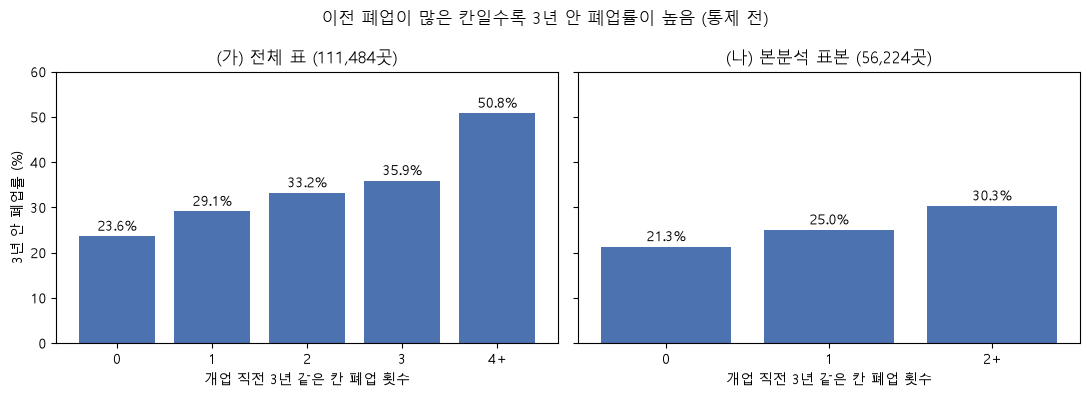

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, table, title in [(axes[0], rate_full, '(가) 전체 표 (111,484곳)'),
                         (axes[1], rate_main, f'(나) 본분석 표본 ({len(main):,}곳)')]:
    bars = ax.bar(table.index.astype(str), table['3년 안 폐업률(%)'], color='#4C72B0')
    ax.bar_label(bars, fmt='%.1f%%', padding=2)
    ax.set_title(title)
    ax.set_xlabel('개업 직전 3년 같은 칸 폐업 횟수')
axes[0].set_ylabel('3년 안 폐업률 (%)')
axes[0].set_ylim(0, 60)
fig.suptitle('이전 폐업이 많은 칸일수록 3년 안 폐업률이 높음 (통제 전)')
plt.tight_layout(); plt.show()

## 3. Kaplan–Meier 생존곡선 (본분석 표본)

이전 폐업 0번 / 1번 / 2번 이상 세 집단. 가로축 = 개업 후 연수, 세로축 = 영업 지속 비율.
양도는 폐업으로 세지 않는다 (`event_ours`). 세 집단 곡선이 같은지 **log-rank 검정**으로 확인한다.

log-rank chi2 = 69.4, df = 2, p = <0.001


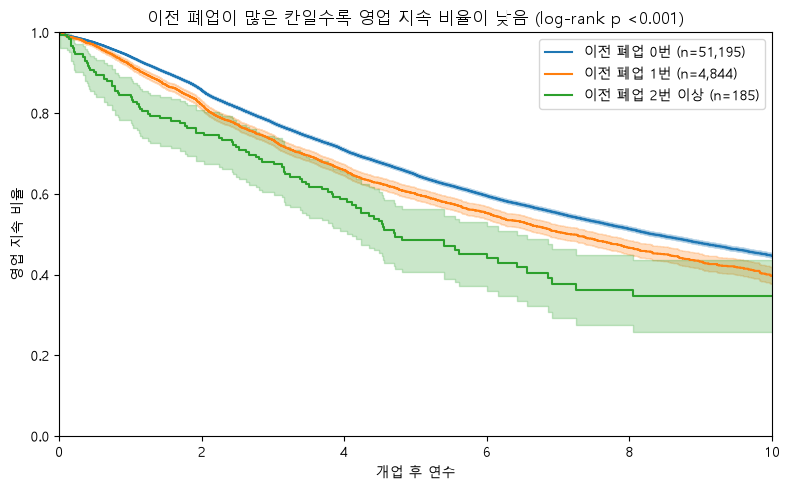

In [6]:
main['years'] = main['duration_days'] / 365.25
labels = {'0': '이전 폐업 0번', '1': '이전 폐업 1번', '2+': '이전 폐업 2번 이상'}

fig, ax = plt.subplots(figsize=(8, 5))
for group, label in labels.items():
    part = main[main['prior_group'] == group]
    kmf = KaplanMeierFitter()
    kmf.fit(part['years'], event_observed=part['event_ours'], label=f'{label} (n={len(part):,})')
    kmf.plot_survival_function(ax=ax, ci_show=True)

test = multivariate_logrank_test(main['years'], main['prior_group'], main['event_ours'])
p_text = '<0.001' if test.p_value < 0.001 else f'{test.p_value:.3f}'
print(f'log-rank chi2 = {test.test_statistic:.1f}, df = 2, p = {p_text}')

ax.set_xlim(0, 10); ax.set_ylim(0, 1)
ax.set_xlabel('개업 후 연수'); ax.set_ylabel('영업 지속 비율')
ax.set_title(f'이전 폐업이 많은 칸일수록 영업 지속 비율이 낮음 (log-rank p {p_text})')
plt.tight_layout(); plt.show()

## 4. 개업 연도별

2022년 개업 가게는 관찰 기간이 짧으므로, 연도 비교에는 **3년 안 폐업 여부(`dead_3y`)만** 사용한다 (전체 표 기준).

,가게 수,이전 폐업 1회 이상(%),3년 안 폐업률(%)
개업 연도,,,
2013,8570,9.3,21.6
2014,10026,11.3,23.3
2015,10128,13.8,23.5
2016,10038,14.8,24.3
2017,11060,18.1,24.4
2018,11352,19.7,24.6
2019,12147,23.4,25.0
2020,12745,26.5,27.8
2021,13078,28.7,30.5


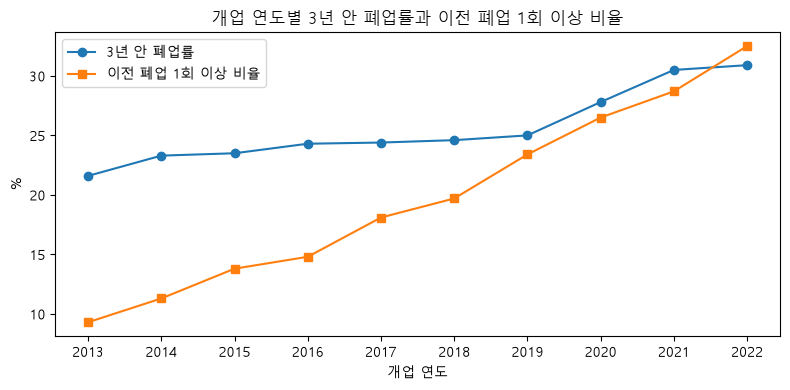

In [7]:
by_year = summary_by(df, 'open_year')
by_year.index.name = '개업 연도'
display(by_year)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_year.index, by_year['3년 안 폐업률(%)'], marker='o', label='3년 안 폐업률')
ax.plot(by_year.index, by_year['이전 폐업 1회 이상(%)'], marker='s', label='이전 폐업 1회 이상 비율')
ax.set_xticks(by_year.index)
ax.set_xlabel('개업 연도'); ax.set_ylabel('%'); ax.legend()
ax.set_title('개업 연도별 3년 안 폐업률과 이전 폐업 1회 이상 비율')
plt.tight_layout(); plt.show()

## 5. 지역 유형별 (`area_rq8`)

골목상권 / 발달상권 / 상권밖 / 전통시장 (전체 표 기준). 지역 유형이 없는 가게는 '결측'으로 표시한다.

In [8]:
area = df.assign(area_rq8=df['area_rq8'].fillna('결측'))
by_area = summary_by(area, 'area_rq8').sort_values('가게 수', ascending=False)
by_area.index.name = '지역 유형'
display(by_area)

,가게 수,이전 폐업 1회 이상(%),3년 안 폐업률(%)
지역 유형,,,
발달상권,45616,25.4,25.3
골목상권,35280,14.7,25.1
상권밖,20145,21.6,28.5
전통시장,9578,17.4,25.1
결측,865,27.6,37.8


## 6. 구별 (25개 구)

전체 표 기준, 3년 안 폐업률이 높은 순서로 정렬. 공개 범위는 구 단위까지 (상호·주소 없음).

In [9]:
by_gu = summary_by(df, 'gu').sort_values('3년 안 폐업률(%)', ascending=False)
by_gu.index.name = '구'
print('구 수:', len(by_gu))
display(by_gu)

구 수: 25


,가게 수,이전 폐업 1회 이상(%),3년 안 폐업률(%)
구,,,
관악구,5247,19.7,30.3
강동구,3303,14.8,29.8
강서구,6311,26.4,29.2
강남구,13124,26.8,28.8
양천구,3319,24.0,28.2
금천구,2728,27.2,27.9
광진구,3925,17.6,27.4
은평구,3912,17.8,27.4
송파구,7123,28.3,27.2


## 7. 관찰 결과

(모두 통제 전 단순 비교이며, 인과가 아니라 **연관**을 보여 준다.)

1. **표본:** 전체 개업 111,484곳 중 단일 점포 칸은 57,842곳, 통제변수 결측을 빼면 본분석 표본은 56,224곳(진짜 폐업 25,229건)이다.
2. **이전 폐업과 3년 안 폐업률:** 전체 표에서 이전 폐업 0번 23.6% → 1번 29.1% → 2번 33.2% → 3번 35.9% → 4번 이상 50.8%로 높아진다. 본분석 표본에서는 0번 21.3% → 1번 25.0% → 2번 이상 30.3%로, 같은 방향이지만 차이가 작다. 전체 표의 4번 이상 집단(4,712곳)은 한 층에 가게가 여럿인 칸이 많아 본분석 표본에서는 대부분 제외된다(본분석 2번 이상 185곳).
3. **생존곡선:** 본분석 표본에서 세 집단의 Kaplan–Meier 곡선은 개업 초기부터 벌어지며, log-rank 검정에서 차이가 있다(χ² = 69.4, df = 2, p < 0.001). 단, 2번 이상 집단은 185곳으로 작아 신뢰구간이 넓다.
4. **개업 연도:** 이전 폐업 1회 이상 비율은 2013년 9.3%에서 2022년 32.5%로, 3년 안 폐업률은 21.6%에서 30.9%로 함께 높아진다. 두 값이 연도와 함께 움직이므로 Cox 모형에서는 개업 연도를 통제한다.
5. **지역:** 3년 안 폐업률은 상권밖(28.5%)이 가장 높고 발달·골목상권·전통시장은 약 25%이다. 구별로는 관악구 30.3%에서 종로구 17.2%까지 차이가 있다.